# Practical 4: Anomaly Detection Using an Autoencoder

**Problem statement:** Use an autoencoder to implement anomaly detection.

The notebook is organized into separate cells for each stage:
- **(a)** Import required libraries
- **(b)** Access and preprocess the dataset
- **(c)** Encode the input into a latent representation
- **(d)** Decode the latent representation back to the original input
- **(e)** Compile the model with an optimizer, loss function, and evaluation metric

For anomaly detection, the model is trained only on images of digit **1** (normal). Images of all other digits are treated as anomalies during evaluation.

## (a) Import required libraries

In [1]:
# (a) Import required libraries

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import mnist

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Set random seeds for reproducibility
tf.random.set_seed(42)
np.random.seed(42)

## (b) Load and preprocess the dataset

In [2]:
# (b) Load the MNIST dataset

(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("Original training images:", x_train.shape)
print("Original test images:", x_test.shape)

Original training images: (60000, 28, 28)
Original test images: (10000, 28, 28)


In [3]:
# (b) Flatten images and normalize pixel values to the range 0–1

x_train = x_train.reshape(-1, 784).astype("float32") / 255.0
x_test = x_test.reshape(-1, 784).astype("float32") / 255.0

NORMAL = 1

# Train only on normal digit-1 images
x_normal = x_train[y_train == NORMAL]

# Select normal test images and 150 anomalous images
rng = np.random.default_rng(42)
norm_idx = np.where(y_test == NORMAL)[0]
anom_idx = rng.choice(
    np.where(y_test != NORMAL)[0],
    size=150,
    replace=False
)

idx = np.concatenate([norm_idx, anom_idx])
rng.shuffle(idx)

x_eval = x_test[idx]

# Labels: 0 = normal, 1 = anomaly
y_eval = (y_test[idx] != NORMAL).astype(int)

print("Normal training samples:", x_normal.shape[0])
print("Total test samples:", len(idx))
print("Normal test samples:", np.sum(y_eval == 0))
print("Anomaly test samples:", np.sum(y_eval == 1))
print("Flattened image shape:", x_normal.shape[1])

Normal training samples: 6742
Total test samples: 1285
Normal test samples: 1135
Anomaly test samples: 150
Flattened image shape: 784


## (c) Define the encoder and latent representation

In [4]:
# (c) Encoder: compress each 784-feature input into a 16-dimensional latent representation

inp = keras.Input(shape=(784,), name="input_image")

e = layers.Dense(128, activation="relu", name="encoder_dense_1")(inp)
e = layers.Dense(64, activation="relu", name="encoder_dense_2")(e)

code = layers.Dense(
    16,
    activation="relu",
    name="latent"
)(e)

encoder = keras.Model(inp, code, name="Encoder")
print("Encoder output shape:", encoder.output_shape)
encoder.summary()

Encoder output shape: (None, 16)


Model: "Encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)             │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ encoder_dense_1 (Dense)              │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ encoder_dense_2 (Dense)              │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ latent (Dense)                       │ (None, 16)                  │           1,040 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 109,776 (428.81 KB)

 Trainable params: 109,776 (428.81 KB)

 Non-trainable params: 0 (0.00 B)

## (d) Define the decoder and complete autoencoder

In [5]:
# (d) Decoder: reconstruct the original 784-feature input from the latent representation

latent_input = keras.Input(shape=(16,), name="latent_input")

d = layers.Dense(64, activation="relu", name="decoder_dense_1")(latent_input)
d = layers.Dense(128, activation="relu", name="decoder_dense_2")(d)
out = layers.Dense(784, activation="sigmoid", name="reconstructed_output")(d)

decoder = keras.Model(latent_input, out, name="Decoder")

# Connect encoder and decoder to create the complete autoencoder
autoencoder = keras.Model(
    inp,
    decoder(encoder(inp)),
    name="MNIST_Autoencoder"
)

print("Autoencoder model summary:")
autoencoder.summary()

Autoencoder model summary:


Model: "MNIST_Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)             │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ Encoder (Functional)                 │ (None, 16)                  │         109,776 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ Decoder (Functional)                 │ (None, 784)                 │         110,544 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 220,320 (860.62 KB)

 Trainable params: 220,320 (860.62 KB)

 Non-trainable params: 0 (0.00 B)

## (e) Compile the autoencoder

In [6]:
# (e) Compile with optimizer, loss function, and evaluation metric

autoencoder.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

print("Autoencoder compiled successfully.")

Autoencoder compiled successfully.


## Train the autoencoder

In [7]:
# Train only on normal images; input and target are the same image

history = autoencoder.fit(
    x_normal,
    x_normal,
    epochs=30,
    batch_size=128,
    validation_split=0.1,
    shuffle=True,
    verbose=2
)

Epoch 1/30
48/48 - 4s - 86ms/step - loss: 0.0876 - mae: 0.1931 - val_loss: 0.0227 - val_mae: 0.0476
Epoch 2/30
48/48 - 1s - 20ms/step - loss: 0.0216 - mae: 0.0418 - val_loss: 0.0177 - val_mae: 0.0373
Epoch 3/30
48/48 - 1s - 13ms/step - loss: 0.0183 - mae: 0.0369 - val_loss: 0.0157 - val_mae: 0.0339
Epoch 4/30
48/48 - 1s - 12ms/step - loss: 0.0168 - mae: 0.0348 - val_loss: 0.0148 - val_mae: 0.0326
Epoch 5/30
48/48 - 1s - 12ms/step - loss: 0.0162 - mae: 0.0338 - val_loss: 0.0142 - val_mae: 0.0318
Epoch 6/30
48/48 - 1s - 13ms/step - loss: 0.0149 - mae: 0.0320 - val_loss: 0.0122 - val_mae: 0.0283
Epoch 7/30
48/48 - 1s - 12ms/step - loss: 0.0132 - mae: 0.0290 - val_loss: 0.0113 - val_mae: 0.0268
Epoch 8/30
48/48 - 1s - 13ms/step - loss: 0.0121 - mae: 0.0277 - val_loss: 0.0099 - val_mae: 0.0248
Epoch 9/30
48/48 - 1s - 12ms/step - loss: 0.0099 - mae: 0.0243 - val_loss: 0.0079 - val_mae: 0.0211
Epoch 10/30
48/48 - 1s - 21ms/step - loss: 0.0082 - mae: 0.0217 - val_loss: 0.0069 - val_mae: 0.0196

## Calculate reconstruction errors and detect anomalies

In [8]:
# Calculate the mean squared reconstruction error for each image

def rec_error(x):
    reconstructed = autoencoder.predict(x, verbose=0)
    return np.mean((x - reconstructed) ** 2, axis=1)

# Reconstruction errors for normal training images
train_err = rec_error(x_normal)

# Set threshold using normal training errors
threshold = train_err.mean() + 2 * train_err.std()

# Reconstruction errors for evaluation images
err = rec_error(x_eval)

# Predict anomalies: 1 = anomaly, 0 = normal
y_pred = (err > threshold).astype(int)

print("Anomaly threshold (mean + 2*std):", round(threshold, 5))

Anomaly threshold (mean + 2*std): 0.01035


## Evaluate anomaly-detection performance

In [9]:
# Compare reconstruction errors for normal and anomalous images

print(
    "Mean reconstruction error - normal:",
    round(err[y_eval == 0].mean(), 5)
)
print(
    "Mean reconstruction error - anomaly:",
    round(err[y_eval == 1].mean(), 5)
)

print("\nROC-AUC Score:", round(roc_auc_score(y_eval, err), 4))

print("\nConfusion Matrix [[TN, FP], [FN, TP]]:")
print(confusion_matrix(y_eval, y_pred, labels=[0, 1]))

print("\nClassification Report:")
print(
    classification_report(
        y_eval,
        y_pred,
        labels=[0, 1],
        target_names=["normal", "anomaly"],
        digits=4,
        zero_division=0
    )
)

Mean reconstruction error - normal: 0.0036
Mean reconstruction error - anomaly: 0.07052

ROC-AUC Score: 0.9994

Confusion Matrix [[TN, FP], [FN, TP]]:
[[1095   40]
 [   0  150]]

Classification Report:
              precision    recall  f1-score   support

      normal     1.0000    0.9648    0.9821      1135
     anomaly     0.7895    1.0000    0.8824       150

    accuracy                         0.9689      1285
   macro avg     0.8947    0.9824    0.9322      1285
weighted avg     0.9754    0.9689    0.9704      1285



## Visualize training loss and reconstruction-error distributions

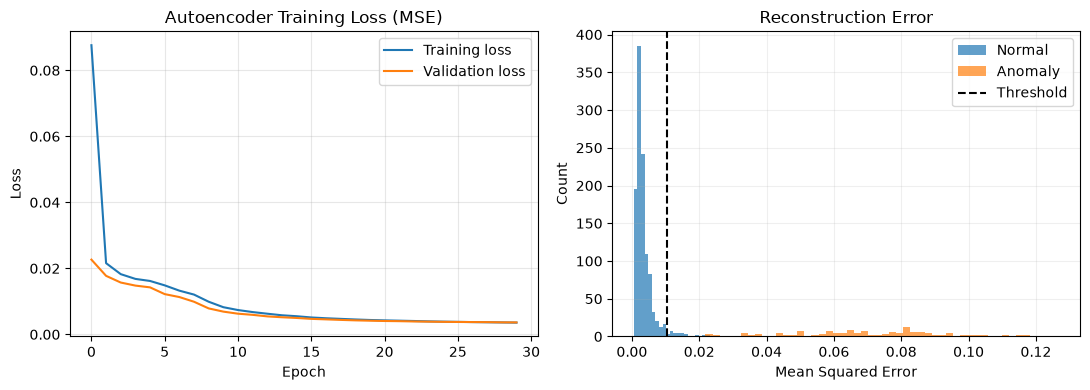

In [10]:
# Plot training/validation loss and reconstruction errors for normal vs anomalous images

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].plot(history.history["loss"], label="Training loss")
ax[0].plot(history.history["val_loss"], label="Validation loss")
ax[0].set_title("Autoencoder Training Loss (MSE)")
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Loss")
ax[0].legend()
ax[0].grid(alpha=0.3)

ax[1].hist(err[y_eval == 0], bins=50, alpha=0.7, label="Normal")
ax[1].hist(err[y_eval == 1], bins=50, alpha=0.7, label="Anomaly")
ax[1].axvline(threshold, color="black", linestyle="--", label="Threshold")
ax[1].set_title("Reconstruction Error")
ax[1].set_xlabel("Mean Squared Error")
ax[1].set_ylabel("Count")
ax[1].legend()
ax[1].grid(alpha=0.2)

plt.tight_layout()
plt.savefig("a4_error.png", dpi=130, bbox_inches="tight")
plt.show()
plt.close(fig)

## Display original and reconstructed images

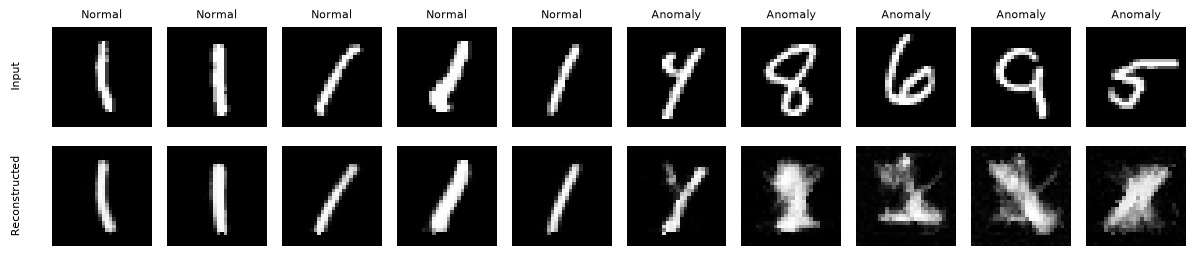

In [11]:
# Display five normal and five anomalous images with their reconstructions

normal_samples = np.where(y_eval == 0)[0][:5]
anomaly_samples = np.where(y_eval == 1)[0][:5]
sel = list(normal_samples) + list(anomaly_samples)

rec = autoencoder.predict(x_eval[sel], verbose=0)

fig, ax = plt.subplots(2, 10, figsize=(12, 2.8))

for i, k in enumerate(sel):
    # Original input
    ax[0, i].imshow(
        x_eval[k].reshape(28, 28),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    ax[0, i].axis("off")
    ax[0, i].set_title(
        "Normal" if y_eval[k] == 0 else "Anomaly",
        fontsize=8
    )

    # Reconstructed output
    ax[1, i].imshow(
        rec[i].reshape(28, 28),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    ax[1, i].axis("off")

ax[0, 0].text(
    -0.3, 0.5, "Input",
    transform=ax[0, 0].transAxes,
    rotation=90,
    va="center",
    ha="right",
    fontsize=8
)
ax[1, 0].text(
    -0.3, 0.5, "Reconstructed",
    transform=ax[1, 0].transAxes,
    rotation=90,
    va="center",
    ha="right",
    fontsize=8
)

plt.tight_layout()
plt.savefig("a4_recon.png", dpi=130, bbox_inches="tight")
plt.show()
plt.close(fig)

## Result and conclusion

In [12]:
print("Practical 4 completed successfully.")
print("Graph 1 saved as: a4_error.png")
print("Graph 2 saved as: a4_recon.png")

Practical 4 completed successfully.
Graph 1 saved as: a4_error.png
Graph 2 saved as: a4_recon.png


The autoencoder was implemented using the MNIST dataset. The encoder compresses each image into a 16-dimensional latent representation, and the decoder reconstructs the input image. The model is trained using normal digit-1 images and uses reconstruction error to identify potential anomalies. The confusion matrix, classification report, ROC-AUC score, loss graph, reconstruction-error distribution, and example reconstructions help assess its performance.

Record the actual evaluation metrics produced when you run the notebook. Results can vary with the runtime environment and training behavior.